# Bures Mean-Field Convergence with Smooth Lasso

This notebook integrates the covariance-only Bures gradient flow for the two-layer linear mean-field model with a whitened quadratic prediction risk plus a smoothed entrywise L1 penalty. The user-facing teacher `oracle_uv` has shape `(d_u, d_v)`, while the paper uses the lower-left predictor block $S_{vu}=S_{uv}^\top$ with shape `(d_v, d_u)`. Thus the data term is centered at `oracle_uv.T`.

The predictor objective is

$$
\ell(S_{vu})
= \frac12\|S_{vu}-S_{\rm teach}\|_F^2
+ \lambda\sum_{i,j}\left(\sqrt{(S_{vu})_{ij}^2+\delta^2}-\delta\right),
\qquad S_{\rm teach}=\texttt{oracle\_uv.T}.
$$

The Bures force uses

$$
E=\nabla\ell(S_{vu})
= S_{vu}-S_{\rm teach}
+ \lambda\frac{S_{vu}}{\sqrt{S_{vu}\odot S_{vu}+\delta^2}},
$$

where the fraction is taken entrywise. With $C_z=I$, the quadratic data term supplies the global PL constant

$$
\kappa=1,
\qquad
L=1+\frac{\lambda}{\delta}.
$$

The regularizer shifts the minimizer away from the teacher. We therefore compute the regularized minimizer $S_{\rm reg}$ entrywise, store `loss` as the gap $\ell(S_{vu})-\ell(S_{\rm reg})$, and store `predictor_error_fro` as $\|S_{vu}-S_{\rm reg}\|_F$.

The covariance is partitioned as

$$
\Sigma =
\begin{pmatrix}
\Sigma^u & \Sigma^{uv} \\
\Sigma^{vu} & \Sigma^v
\end{pmatrix},
\qquad
G =
\begin{pmatrix}
0 & E^\top \\
E & 0
\end{pmatrix}.
$$

We solve

$$
\dot\Sigma = -(G\Sigma + \Sigma G)
$$

with SciPy's explicit Runge-Kutta solvers and the paper's time normalization (gradient flow of $n\ell(VU^\top/n)$ in the factors).

This notebook follows `paper_iclr_no_hi`: its general support-gap theorem does **not** require hyperbolic isotropy. For $J=\operatorname{diag}(I_{d_u},-I_{d_v})$, let $\lambda_1\le\cdots\le\lambda_m$ be the eigenvalues of $\Sigma_0^{1/2}J\Sigma_0^{1/2}$, **including zeros**. Then
$$
a_+=\max(\lambda_{d_v+1},0),\quad a_-=\max(-\lambda_{d_v},0),\quad g=a_++a_-,\qquad
\Delta_t\le\Delta_0 e^{-2\kappa g t}.
$$
For $\Sigma_0=\alpha I$, $\alpha=\sigma^2$ is a variance, $g=2\alpha$, and the certified exponent is $4\alpha\kappa$. This is a sufficient uniform envelope, not a fitted or necessarily attained asymptotic rate. A zero gap gives no positive-rate guarantee.

The scalar Hessian entries are $1+\lambda\delta^2/(s^2+\delta^2)^{3/2}\in[1,1+\lambda/\delta]$. Hence the loss is globally 1-strongly convex and satisfies the paper's smooth PL assumption with the constants above. This is product-level regularization, not separate factor regularization; exact covariance closure and spectral conservation are preserved. Positive smoothing does not generally produce exact sparsity, and $\delta=0$ is outside the smooth theorem.

**Numerical protocol.** Float64, Gaussian teacher `default_rng(0)` divided by $\sqrt{d_u}$, dimensions $(16,9)$, covariance RK45 tolerances $10^{-9}/10^{-11}$ and factor RK45 tolerances $10^{-8}/10^{-10}$. Finite-width seeds are `10000 + 1000*n + trial`. The factor equations are integrated directly. Loss gaps use a cancellation-resistant Bregman expression about the numerically computed regularized minimizer. The single-panel plots hide values below $10^{-14}$; the appendix triptych instead shows raw loss gaps down to an axis minimum of $10^{-23}$ to expose numerical tails. Arrays remain unchanged. Tail-rate estimates are descriptive fits above a numerical cutoff, never used to construct the envelopes. PDF/PNG export needs no LaTeX; PGF export is optional via `EXPORT_PGF` (or environment variable `LASSO_EXPORT_PGF=1`).



In [1]:
from __future__ import annotations

import os
from dataclasses import dataclass
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np
from typing import Optional
from numpy.typing import NDArray
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

Array = NDArray[np.float64]

LASSO_LAMBDA = 0.1
LASSO_DELTA = 0.01
PL_KAPPA = 1.0
EXPORT_PGF = os.environ.get("LASSO_EXPORT_PGF", "0") == "1"
DISPLAY_FLOOR = 1e-14

SMOOTHNESS_L = 1.0 + LASSO_LAMBDA / LASSO_DELTA

plt.rcParams.update({
    "font.size": 6,
    "font.family": "serif",
    "axes.titlesize": 8,
    "axes.labelsize": 6,
    "legend.fontsize": 6,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "pgf.texsystem": "pdflatex",
    "pgf.rcfonts": False,
    "pgf.preamble": "\n".join([
        r"\usepackage{amsfonts}",
        r"\usepackage{amssymb}",
    ]),
})

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "code" / "figures").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the repository")

FIG_DIR = ROOT / "code" / "figures"
RESULTS_DIR = ROOT / "code" / "notebooks" / "research" / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_SIZE = (4.0, 3.0)
SINGLE_PANEL_SIZE = (4.0, 2.35)
TWO_PANEL_SIZE = (6.0, 2.35)
THREE_PANEL_SIZE = (6.0, 2.25)
GRID_STYLE = {"which": "both", "color": "#E8E8E8", "linewidth": 0.8}
COLORS = ["#2458A6", "#D1495B", "#00876C", "#7A3E9D", "#E08D2D", "#2B8CBE"]

def save_figure(fig, output, *, dpi=200, formats=None):
    if output is None:
        return

    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    formats = formats or (("pdf", "png", "pgf") if EXPORT_PGF else ("pdf", "png"))
    for suffix in formats:
        fig.savefig(output.with_suffix(f".{suffix}"), dpi=dpi)

## Core Bures Flow Utilities

In [2]:
@dataclass(frozen=True)
class FlowConfig:
    d_u: int
    d_v: int
    oracle_uv: Array
    sigma0: Array
    lasso_lambda: float = LASSO_LAMBDA
    lasso_delta: float = LASSO_DELTA
    t_final: float = 80.0
    n_eval: int = 801
    rtol: float = 1e-9
    atol: float = 1e-11
    method: str = "RK45"


@dataclass(frozen=True)
class FlowResult:
    t: Array
    sigma: Array
    loss: Array
    predictor_error_fro: Array
    min_eig_sigma: Array
    signed_spectrum_drift: Array
    loss_rate: float
    error_rate: float
    success: bool
    message: str
    nfev: int


@dataclass(frozen=True)
class ParticleConfig:
    d_u: int
    d_v: int
    oracle_uv: Array
    n_particles: int
    alpha: float
    lasso_lambda: float = LASSO_LAMBDA
    lasso_delta: float = LASSO_DELTA
    rng_seed: int = 0
    u0: Array | None = None
    v0: Array | None = None
    t_final: float = 80.0
    n_eval: int = 801
    rtol: float = 1e-8
    atol: float = 1e-10
    method: str = "RK45"


@dataclass(frozen=True)
class ParticleResult:
    t: Array
    sigma: Array
    loss: Array
    predictor_error_fro: Array
    min_eig_sigma: Array
    initial_u: Array
    initial_v: Array
    final_u: Array
    final_v: Array
    n_particles: int
    alpha: float
    loss_rate: float
    error_rate: float
    success: bool
    message: str
    nfev: int


def symmetrize(a: Array) -> Array:
    return 0.5 * (a + a.T)


def identity_covariance(d_u: int, d_v: int, scale: float = 1.0) -> Array:
    if scale <= 0:
        raise ValueError("identity covariance scale must be positive")
    return scale * np.eye(d_u + d_v)


def random_oracle_uv(d_u: int, d_v: int, rng: np.random.Generator, scale: float = 1.0) -> Array:
    return scale * rng.standard_normal((d_u, d_v)) / np.sqrt(max(d_u, 1))


def smooth_l1_value(x: Array, delta: float = LASSO_DELTA) -> Array:
    if delta <= 0:
        raise ValueError("lasso_delta must be positive")
    return np.sqrt(x * x + delta * delta) - delta


def smooth_l1_grad(x: Array, delta: float = LASSO_DELTA) -> Array:
    if delta <= 0:
        raise ValueError("lasso_delta must be positive")
    return x / np.sqrt(x * x + delta * delta)


def predictor_objective_and_gradient_vu(
    s_vu: Array,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[float, Array]:
    if lasso_lambda < 0:
        raise ValueError("lasso_lambda must be nonnegative")
    if lasso_delta <= 0:
        raise ValueError("lasso_delta must be positive")
    teacher_vu = oracle_uv.T
    if s_vu.shape != teacher_vu.shape:
        raise ValueError(f"s_vu has shape {s_vu.shape}, expected {teacher_vu.shape}")
    residual_vu = s_vu - teacher_vu
    quadratic = 0.5 * float(np.sum(residual_vu * residual_vu))
    regularizer = lasso_lambda * float(np.sum(smooth_l1_value(s_vu, lasso_delta)))
    gradient = residual_vu + lasso_lambda * smooth_l1_grad(s_vu, lasso_delta)
    return quadratic + regularizer, gradient


def regularized_minimizer_vu(
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> Array:
    if lasso_lambda < 0:
        raise ValueError("lasso_lambda must be nonnegative")
    if lasso_delta <= 0:
        raise ValueError("lasso_delta must be positive")
    teacher_vu = oracle_uv.T
    if lasso_lambda == 0:
        return np.array(teacher_vu, dtype=float, copy=True)

    minimizer = np.empty_like(teacher_vu, dtype=float)
    for index, b in np.ndenumerate(teacher_vu):
        if b == 0:
            minimizer[index] = 0.0
            continue

        def stationarity(x: float) -> float:
            return x - b + lasso_lambda * x / np.sqrt(x * x + lasso_delta * lasso_delta)

        lo, hi = (0.0, float(b)) if b > 0 else (float(b), 0.0)
        minimizer[index] = brentq(stationarity, lo, hi,
                                  xtol=np.nextafter(0.0, 1.0),
                                  rtol=4*np.finfo(float).eps)
    return minimizer


def objective_minimum(
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[Array, float]:
    s_reg = regularized_minimizer_vu(oracle_uv, lasso_lambda, lasso_delta)
    ell_star, _ = predictor_objective_and_gradient_vu(s_reg, oracle_uv, lasso_lambda, lasso_delta)
    return s_reg, ell_star


def initialize_particles_from_isotropic_covariance(
    d_u: int,
    d_v: int,
    n_particles: int,
    alpha: float,
    rng: np.random.Generator,
) -> tuple[Array, Array]:
    if n_particles <= 0:
        raise ValueError("n_particles must be positive")
    if alpha < 0:
        raise ValueError("alpha must be nonnegative")
    scale = np.sqrt(alpha)
    u = scale * rng.standard_normal((d_u, n_particles))
    v = scale * rng.standard_normal((d_v, n_particles))
    return u, v


def empirical_predictor_vu(u: Array, v: Array) -> Array:
    if u.ndim != 2 or v.ndim != 2:
        raise ValueError("u and v must be matrices with particles in columns")
    if u.shape[1] != v.shape[1]:
        raise ValueError("u and v must have the same number of particles")
    return v @ u.T / u.shape[1]


def empirical_covariance_from_particles(u: Array, v: Array) -> Array:
    if u.ndim != 2 or v.ndim != 2:
        raise ValueError("u and v must be matrices with particles in columns")
    if u.shape[1] != v.shape[1]:
        raise ValueError("u and v must have the same number of particles")
    particles = np.vstack([u, v])
    return symmetrize(particles @ particles.T / u.shape[1])


def particle_loss_and_field(
    u: Array,
    v: Array,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[float, Array]:
    d_u, _n_particles = u.shape
    d_v = v.shape[0]
    if oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {oracle_uv.shape}, expected {(d_u, d_v)}")
    predictor_vu = empirical_predictor_vu(u, v)
    return predictor_objective_and_gradient_vu(predictor_vu, oracle_uv, lasso_lambda, lasso_delta)


def split_blocks(sigma: Array, d_u: int, d_v: int) -> tuple[Array, Array, Array, Array]:
    m = d_u + d_v
    if sigma.shape != (m, m):
        raise ValueError(f"sigma has shape {sigma.shape}, expected {(m, m)}")
    s_u = sigma[:d_u, :d_u]
    s_uv = sigma[:d_u, d_u:]
    s_vu = sigma[d_u:, :d_u]
    s_v = sigma[d_u:, d_u:]
    return s_u, s_uv, s_vu, s_v


def predictor_loss_and_gradient(
    sigma: Array,
    d_u: int,
    d_v: int,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> tuple[float, Array]:
    if oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {oracle_uv.shape}, expected {(d_u, d_v)}")
    _, _, s_vu, _ = split_blocks(sigma, d_u, d_v)
    return predictor_objective_and_gradient_vu(s_vu, oracle_uv, lasso_lambda, lasso_delta)


def bures_rhs_matrix(
    sigma: Array,
    d_u: int,
    d_v: int,
    oracle_uv: Array,
    lasso_lambda: float = LASSO_LAMBDA,
    lasso_delta: float = LASSO_DELTA,
) -> Array:
    _, gradient_vu = predictor_loss_and_gradient(sigma, d_u, d_v, oracle_uv, lasso_lambda, lasso_delta)
    m = d_u + d_v
    g = np.zeros((m, m))
    g[:d_u, d_u:] = gradient_vu.T
    g[d_u:, :d_u] = gradient_vu
    return symmetrize(-(g @ sigma + sigma @ g))


def bures_rhs_flat(
    _t: float,
    y: Array,
    d_u: int,
    d_v: int,
    oracle_uv: Array,
    lasso_lambda: float,
    lasso_delta: float,
) -> Array:
    m = d_u + d_v
    sigma = symmetrize(y.reshape(m, m))
    return bures_rhs_matrix(sigma, d_u, d_v, oracle_uv, lasso_lambda, lasso_delta).reshape(-1)


def signature_matrix(d_u: int, d_v: int) -> Array:
    return np.diag(np.concatenate([np.ones(d_u), -np.ones(d_v)]))


def predictor_block_norms(result: FlowResult, d_u: int, d_v: int) -> Array:
    return np.array([
        np.linalg.norm(split_blocks(sigma, d_u, d_v)[2], ord="fro")
        for sigma in result.sigma
    ])


def empirical_sublevel_radius(result: FlowResult, d_u: int, d_v: int) -> float:
    return float(np.max(predictor_block_norms(result, d_u, d_v)))


def coarse_ellipticity_constant(alpha: float, m: int, M: float) -> float:
    denominator = np.sqrt(m * alpha**2 + 2.0 * M**2) + M
    return float(alpha * (alpha / denominator) ** (m - 1))


def estimate_exponential_rate(
    t: Array,
    values: Array,
    tail_fraction: float = 0.5,
    floor: float = 1e-10,
    relative_floor: float = 1e-8,
) -> float:
    if not (0 < tail_fraction <= 1):
        raise ValueError("tail_fraction must be in (0, 1]")
    values = np.asarray(values)
    finite_positive = values[np.isfinite(values) & (values > 0)]
    if len(finite_positive) < 3:
        return float("nan")
    threshold = max(floor, float(finite_positive[0]) * relative_floor)
    mask = np.isfinite(values) & (values > threshold)
    if np.count_nonzero(mask) < 3:
        return float("nan")
    t_fit = t[mask]
    v_fit = values[mask]
    start = max(0, int(np.floor((1.0 - tail_fraction) * len(t_fit))))
    if len(t_fit) - start < 3:
        start = max(0, len(t_fit) - 3)
    slope, _intercept = np.polyfit(t_fit[start:], np.log(v_fit[start:]), deg=1)
    return float(-slope)


def signed_spectrum(sigma: Array, d_u: int) -> Array:
    """Symmetric representation of spec(J Sigma), retaining all zero indices."""
    values, vectors = np.linalg.eigh(symmetrize(sigma))
    tolerance = 1e-8 * max(1.0, float(np.max(np.abs(values))))
    if values.min() < -tolerance:
        raise ValueError("Covariance is not positive semidefinite within solver tolerance")
    root = (vectors * np.sqrt(np.maximum(values, 0.0))) @ vectors.T
    return np.linalg.eigvalsh(symmetrize(root @ signature_matrix(d_u, len(sigma)-d_u) @ root))


def support_gap(sigma: Array, d_u: int) -> float:
    spectrum = signed_spectrum(sigma, d_u)
    d_v = len(sigma)-d_u
    return float(max(spectrum[d_v], 0.0) + max(-spectrum[d_v-1], 0.0))


def stable_loss_gap(s_vu, s_reg, lasso_lambda, lasso_delta):
    # h(x)-h(z)-h'(z)(x-z) rationalized to avoid subtracting O(1) objectives.
    # This equals the objective gap for the exact minimizer z. The validation
    # cell bounds the residual error from the float64 approximation to z.
    difference = s_vu-s_reg
    hx, hz = np.hypot(s_vu, lasso_delta), np.hypot(s_reg, lasso_delta)
    bregman = lasso_delta**2 * difference**2 / (
        hz * (hx*hz + s_vu*s_reg + lasso_delta**2))
    return float(np.sum(0.5*difference**2 + lasso_lambda*bregman))


def sublevel_radius_bound(result, d_u, d_v, kappa=1.0):
    # Strong convexity: every point in the initial sublevel set is within
    # sqrt(2 Delta_0/kappa) of the minimizer, including S_0 itself.
    s0 = result.sigma[0, d_u:, :d_u]
    return float(np.linalg.norm(s0) + 2*np.sqrt(2*result.loss[0]/kappa))


def visible(values):
    return np.where(np.asarray(values) >= DISPLAY_FLOOR, values, np.nan)


In [3]:
def solve_bures_flow(config: FlowConfig) -> FlowResult:
    d_u, d_v = config.d_u, config.d_v
    m = d_u + d_v
    if config.sigma0.shape != (m, m):
        raise ValueError(f"sigma0 has shape {config.sigma0.shape}, expected {(m, m)}")
    if config.oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {config.oracle_uv.shape}, expected {(d_u, d_v)}")
    sigma0 = symmetrize(np.array(config.sigma0, dtype=float, copy=True))
    t_eval = np.linspace(0.0, config.t_final, config.n_eval)
    sol = solve_ivp(
        bures_rhs_flat,
        t_span=(0.0, config.t_final),
        y0=sigma0.reshape(-1),
        args=(d_u, d_v, config.oracle_uv, config.lasso_lambda, config.lasso_delta),
        method=config.method,
        t_eval=t_eval,
        rtol=config.rtol,
        atol=config.atol,
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    sigma_path = np.empty((len(sol.t), m, m))
    loss = np.empty(len(sol.t))
    error = np.empty(len(sol.t))
    min_eig = np.empty(len(sol.t))
    invariant_drift = np.empty(len(sol.t))
    invariant0 = signed_spectrum(sigma0, d_u)
    invariant0_norm = max(1.0, float(np.linalg.norm(invariant0)))
    s_reg, ell_star = objective_minimum(config.oracle_uv, config.lasso_lambda, config.lasso_delta)

    for k, y in enumerate(sol.y.T):
        sigma = symmetrize(y.reshape(m, m))
        sigma_path[k] = sigma
        objective, gradient_vu = predictor_loss_and_gradient(
            sigma,
            d_u,
            d_v,
            config.oracle_uv,
            config.lasso_lambda,
            config.lasso_delta,
        )
        _, _, s_vu, _ = split_blocks(sigma, d_u, d_v)
        loss[k] = stable_loss_gap(s_vu, s_reg, config.lasso_lambda, config.lasso_delta)
        error[k] = float(np.linalg.norm(s_vu - s_reg, ord="fro"))
        min_eig[k] = float(np.linalg.eigvalsh(sigma).min())
        invariant = signed_spectrum(sigma, d_u)
        invariant_drift[k] = float(np.linalg.norm(invariant - invariant0) / invariant0_norm)

    return FlowResult(
        t=sol.t,
        sigma=sigma_path,
        loss=loss,
        predictor_error_fro=error,
        min_eig_sigma=min_eig,
        signed_spectrum_drift=invariant_drift,
        loss_rate=estimate_exponential_rate(sol.t, loss, relative_floor=1e-10),
        error_rate=estimate_exponential_rate(sol.t, error, relative_floor=1e-6),
        success=bool(sol.success),
        message=str(sol.message),
        nfev=int(sol.nfev),
    )


def summarize_result(
    label: str,
    result: FlowResult,
    *,
    alpha: float | None = None,
    d_u: int | None = None,
    d_v: int | None = None,
    kappa: float = 1.0,
) -> dict[str, float | str | bool | int]:
    row = {
        "label": label,
        "initial_loss": result.loss[0],
        "final_loss": result.loss[-1],
        "initial_distance_to_minimizer_fro": result.predictor_error_fro[0],
        "final_distance_to_minimizer_fro": result.predictor_error_fro[-1],
        "tail_loss_rate": result.loss_rate,
        "tail_error_rate": result.error_rate,
        "min_eig_sigma_final": result.min_eig_sigma[-1],
        "max_signed_spectrum_drift": float(np.max(result.signed_spectrum_drift)),
        "success": result.success,
        "nfev": result.nfev,
    }
    if d_u is not None and d_v is not None:
        g0 = support_gap(result.sigma[0], d_u)
        row.update({"support_gap": g0, "certified_loss_rate": 2*kappa*g0})
        if alpha is not None and alpha > 0 and np.allclose(result.sigma[0], alpha*np.eye(d_u+d_v)):
            M_bound = sublevel_radius_bound(result, d_u, d_v, kappa)
            c_coarse = coarse_ellipticity_constant(alpha, d_u+d_v, M_bound)
            row.update({"M_bound": M_bound, "c_coarse": c_coarse,
                        "coarse_loss_rate": 4*c_coarse*kappa,
                        "coarse_over_spectral": c_coarse/alpha})
    return row


def resolve_plot_colors(colors, n: int) -> list:
    if n <= 0:
        return []
    if colors is None:
        colors = COLORS
    if isinstance(colors, str):
        try:
            cmap = plt.get_cmap(colors)
        except ValueError:
            if not mcolors.is_color_like(colors):
                raise
            return [colors] * n
        samples = np.linspace(0.15, 0.85, n) if n > 1 else np.array([0.5])
        return [cmap(sample) for sample in samples]
    if callable(colors):
        samples = np.linspace(0.15, 0.85, n) if n > 1 else np.array([0.5])
        return [colors(sample) for sample in samples]
    if mcolors.is_color_like(colors):
        return [colors] * n
    palette = list(colors)
    if not palette:
        raise ValueError("colors must contain at least one color")
    return [palette[idx % len(palette)] for idx in range(n)]


def save_figure(fig, output, *, dpi=200, formats=None):
    if output is None:
        return
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    formats = formats or (("pdf", "png", "pgf") if EXPORT_PGF else ("pdf", "png"))
    for suffix in formats:
        fig.savefig(output.with_suffix(f".{suffix}"), dpi=dpi)


def finish_axes(ax, *, title=None, xlabel="time", ylabel=None, yscale="log", legend=None):
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if yscale:
        ax.set_yscale(yscale)
    ax.grid(True, **GRID_STYLE)
    if legend:
        ax.legend(**legend)


def particle_rhs_flat(
    _t: float,
    y: Array,
    d_u: int,
    d_v: int,
    n_particles: int,
    oracle_uv: Array,
    lasso_lambda: float,
    lasso_delta: float,
) -> Array:
    particles = y.reshape(d_u + d_v, n_particles)
    u = particles[:d_u, :]
    v = particles[d_u:, :]
    _, field_vu = particle_loss_and_field(u, v, oracle_uv, lasso_lambda, lasso_delta)
    du = -(field_vu.T @ v)
    dv = -(field_vu @ u)
    return np.vstack([du, dv]).reshape(-1)


def solve_particle_flow(config: ParticleConfig) -> ParticleResult:
    d_u, d_v = config.d_u, config.d_v
    n_particles = config.n_particles
    if config.oracle_uv.shape != (d_u, d_v):
        raise ValueError(f"oracle_uv has shape {config.oracle_uv.shape}, expected {(d_u, d_v)}")
    if n_particles <= 0:
        raise ValueError("n_particles must be positive")

    if config.u0 is None or config.v0 is None:
        if config.u0 is not None or config.v0 is not None:
            raise ValueError("u0 and v0 must be provided together")
        rng = np.random.default_rng(config.rng_seed)
        u0, v0 = initialize_particles_from_isotropic_covariance(
            d_u, d_v, n_particles, config.alpha, rng
        )
    else:
        u0 = np.array(config.u0, dtype=float, copy=True)
        v0 = np.array(config.v0, dtype=float, copy=True)
        if u0.shape != (d_u, n_particles):
            raise ValueError(f"u0 has shape {u0.shape}, expected {(d_u, n_particles)}")
        if v0.shape != (d_v, n_particles):
            raise ValueError(f"v0 has shape {v0.shape}, expected {(d_v, n_particles)}")

    y0 = np.vstack([u0, v0]).reshape(-1)
    t_eval = np.linspace(0.0, config.t_final, config.n_eval)
    sol = solve_ivp(
        particle_rhs_flat,
        t_span=(0.0, config.t_final),
        y0=y0,
        args=(d_u, d_v, n_particles, config.oracle_uv, config.lasso_lambda, config.lasso_delta),
        method=config.method,
        t_eval=t_eval,
        rtol=config.rtol,
        atol=config.atol,
    )

    m = d_u + d_v
    if not sol.success:
        raise RuntimeError(sol.message)

    sigma_path = np.empty((len(sol.t), m, m))
    loss = np.empty(len(sol.t))
    error = np.empty(len(sol.t))
    min_eig = np.empty(len(sol.t))
    s_reg, ell_star = objective_minimum(config.oracle_uv, config.lasso_lambda, config.lasso_delta)

    for k, y in enumerate(sol.y.T):
        particles = y.reshape(m, n_particles)
        u = particles[:d_u, :]
        v = particles[d_u:, :]
        sigma = empirical_covariance_from_particles(u, v)
        sigma_path[k] = sigma
        objective, field_vu = particle_loss_and_field(
            u,
            v,
            config.oracle_uv,
            config.lasso_lambda,
            config.lasso_delta,
        )
        predictor_vu = empirical_predictor_vu(u, v)
        loss[k] = stable_loss_gap(predictor_vu, s_reg, config.lasso_lambda, config.lasso_delta)
        error[k] = float(np.linalg.norm(predictor_vu - s_reg, ord="fro"))
        min_eig[k] = float(np.linalg.eigvalsh(sigma).min())

    final_particles = sol.y[:, -1].reshape(m, n_particles)
    return ParticleResult(
        t=sol.t,
        sigma=sigma_path,
        loss=loss,
        predictor_error_fro=error,
        min_eig_sigma=min_eig,
        initial_u=u0,
        initial_v=v0,
        final_u=final_particles[:d_u, :],
        final_v=final_particles[d_u:, :],
        n_particles=n_particles,
        alpha=config.alpha,
        loss_rate=estimate_exponential_rate(sol.t, loss, relative_floor=1e-10),
        error_rate=estimate_exponential_rate(sol.t, error, relative_floor=1e-6),
        success=bool(sol.success),
        message=str(sol.message),
        nfev=int(sol.nfev),
    )


def summarize_particle_result(label: str, result: ParticleResult) -> dict[str, float | str | bool | int]:
    return {
        "label": label,
        "n_particles": result.n_particles,
        "alpha": result.alpha,
        "initial_loss": result.loss[0],
        "final_loss": result.loss[-1],
        "initial_distance_to_minimizer_fro": result.predictor_error_fro[0],
        "final_distance_to_minimizer_fro": result.predictor_error_fro[-1],
        "tail_loss_rate": result.loss_rate,
        "tail_error_rate": result.error_rate,
        "min_eig_sigma_initial": result.min_eig_sigma[0],
        "min_eig_sigma_final": result.min_eig_sigma[-1],
        "success": result.success,
        "nfev": result.nfev,
    }


def particle_result_list(result_or_results) -> list[ParticleResult]:
    if isinstance(result_or_results, ParticleResult):
        return [result_or_results]
    return list(result_or_results)


def finite_width_curve_stats(
    results: list[ParticleResult],
    quantity: str = "loss",
    reference: FlowResult | None = None,
) -> tuple[Array, Array, Array]:
    if not results:
        raise ValueError("results must contain at least one repeat")
    t = results[0].t
    curves = []
    for result in results:
        if not np.allclose(result.t, t):
            raise ValueError("all repeats must use the same time grid")
        if quantity == "loss":
            curve = result.loss
        elif quantity == "covariance_error":
            if reference is None:
                raise ValueError("reference is required for covariance_error")
            curve = np.linalg.norm(result.sigma - reference.sigma, ord="fro", axis=(1, 2))
        else:
            raise ValueError(f"unknown quantity {quantity!r}")
        curves.append(curve)
    curves = np.vstack(curves)
    return t, np.mean(curves, axis=0), np.std(curves, axis=0, ddof=1 if len(results) > 1 else 0)


def plot_mean(
    ax,
    t: Array,
    mean: Array,
    *,
    color,
    label: str,
    linewidth: float = 1.35,
    band_alpha: float = 0.16,
):
    ax.plot(t, visible(mean), color=color, linewidth=linewidth, label=label)


def overplot_individual_curves(ax, curves: list[Array], t: Array, *, color, alpha: float = 0.18):
    for curve in curves:
        ax.plot(t, visible(curve), color=color, linewidth=0.6, alpha=alpha, label="_nolegend_")


def plot_finite_width_comparison(
    mean_field_result: FlowResult,
    particle_results_by_width: dict[int, ParticleResult | list[ParticleResult]],
    *,
    output=None,
    figsize=SINGLE_PANEL_SIZE,
    colors=None,
    show_individual: bool = True,
) -> None:
    legend_height = 0.82
    fig, ax = plt.subplots(
        1,
        1,
        figsize=(figsize[0], figsize[1] + legend_height),
        constrained_layout=False,
    )
    fig.subplots_adjust(left=0.15, right=0.98, top=0.88, bottom=0.25)
    ax.set_yscale("log")
    ax.plot(mean_field_result.t, visible(mean_field_result.loss), color="black", linewidth=1.45, label="mean field")
    plot_colors = resolve_plot_colors(colors, len(particle_results_by_width))
    for idx, (n_particles, result_or_results) in enumerate(particle_results_by_width.items()):
        color = plot_colors[idx]
        results = particle_result_list(result_or_results)
        t, mean, std = finite_width_curve_stats(results, quantity="loss")
        if show_individual:
            overplot_individual_curves(ax, [result.loss for result in results], t, color=color)
        ax.fill_between(t, visible(np.maximum(mean-std, 0)), visible(mean+std), color=color, alpha=0.12)
        plot_mean(
            ax,
            t,
            visible(mean),
            color=color,
            label=rf"$n={n_particles}$",
        )
    finish_axes(ax, title="Finite-width smooth-lasso loss", ylabel=r"$\ell_t-\ell_\star$")
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.04),
        ncol=max(1, len(labels)),
        frameon=True,
    )
    save_figure(fig, output)
    return fig


def plot_finite_width_covariance_error(
    mean_field_result: FlowResult,
    particle_results_by_width: dict[int, ParticleResult | list[ParticleResult]],
    *,
    output=None,
    figsize=SINGLE_PANEL_SIZE,
    colors=None,
    show_individual: bool = True,
) -> None:
    fig, ax = plt.subplots(1, 1, figsize=figsize, constrained_layout=True)
    ax.set_yscale("log")
    plot_colors = resolve_plot_colors(colors, len(particle_results_by_width))
    for idx, (n_particles, result_or_results) in enumerate(particle_results_by_width.items()):
        color = plot_colors[idx]
        results = particle_result_list(result_or_results)
        t, mean, std = finite_width_curve_stats(
            results,
            quantity="covariance_error",
            reference=mean_field_result,
        )
        if show_individual:
            individual_curves = [
                np.linalg.norm(result.sigma - mean_field_result.sigma, ord="fro", axis=(1, 2))
                for result in results
            ]
            overplot_individual_curves(ax, individual_curves, t, color=color)
        ax.fill_between(t, visible(np.maximum(mean-std, 0)), visible(mean+std), color=color, alpha=0.12)
        plot_mean(
            ax,
            t,
            visible(mean),
            color=color,
            label=rf"$n={n_particles}$",
        )
    finish_axes(ax, title="Covariance sampling error", ylabel=r"$\|\widehat\Sigma_t-\Sigma_t\|_F$")
    ax.legend(frameon=True)
    save_figure(fig, output)
    return fig

def plot_trajectory(
    result: FlowResult,
    title: str = "Bures covariance flow",
    *,
    output=None,
    figsize=TWO_PANEL_SIZE,
) -> None:
    fig, axes = plt.subplots(1, 2, figsize=figsize, constrained_layout=True)
    axes[0].plot(result.t, visible(result.loss), color=COLORS[0], linewidth=1.45)
    axes[1].plot(result.t, np.maximum(result.signed_spectrum_drift, 1e-18), color=COLORS[2], linewidth=1.45)
    finish_axes(axes[0], title="Loss gap", ylabel=r"$\ell_t-\ell_\star$")
    finish_axes(axes[1], title="Signed-spectrum drift", ylabel="relative drift")
    if title:
        fig.suptitle(title, fontsize=plt.rcParams["axes.titlesize"])
    save_figure(fig, output)
    plt.show()

def plot_scale_sweep(
    results_by_scale: dict[float, FlowResult],
    d_u: int,
    d_v: int,
    kappa: float = 1.0,
    *,
    output=None,
    figsize=SINGLE_PANEL_SIZE,
    colors=None,
    line_colors = None,
    parameter_label: str = r"\alpha",
    plot_spectral_rate: Optional[list[int]]=None,
    plot_coarse_rate: Optional[list[int]]=None,
    show_legend: bool = True,
) -> None:
    legend_height = 0.82
    fig, ax = plt.subplots(
        1,
        1,
        figsize=(figsize[0], figsize[1] + legend_height),
        constrained_layout=False,
    )
    fig.subplots_adjust(left=0.15, right=0.98, top=0.88, bottom=0.25)
    ax.set_yscale("log")
    plot_colors = resolve_plot_colors(colors, len(results_by_scale))
    line_colors = resolve_plot_colors(line_colors, len(results_by_scale))
    colors_by_alpha: dict[float, str] = {}
    for idx, (alpha, result) in enumerate(results_by_scale.items()):
        color = plot_colors[idx]
        colors_by_alpha[alpha] = color
        ax.plot(result.t, visible(result.loss), color=color, linewidth=1.45, label=rf"${parameter_label}={alpha:g}$")

    empirical_ylim = ax.get_ylim()
    m = d_u + d_v

    line_colors_by_alpha: dict[float, str] = {}
    for ind, (alpha, result) in enumerate(results_by_scale.items()):
        line_color = line_colors[ind]
        line_colors_by_alpha[alpha] = line_color
        M_bound = sublevel_radius_bound(result, d_u, d_v, kappa)
        c_coarse = coarse_ellipticity_constant(alpha, m, M_bound)
        if support_gap(result.sigma[0], d_u) > 1e-12 and (plot_spectral_rate is None or ind in plot_spectral_rate):
            ax.plot(
                result.t,
                result.loss[0] * np.exp(-2.0 * support_gap(result.sigma[0], d_u) * kappa * result.t),
                linestyle="--",
                color=line_color,
                linewidth=1.0,
                alpha=0.65,
                label="_nolegend_",
            )
        if alpha > 0 and np.allclose(result.sigma[0], alpha*np.eye(m)) and (plot_coarse_rate is None or ind in plot_coarse_rate):
            ax.plot(
                result.t,
                result.loss[0] * np.exp(-4.0 * c_coarse * kappa * result.t),
                linestyle=":",
                color=line_color,
                linewidth=1.1,
                alpha=0.8,
                label="_nolegend_",
            )

    ax.set_ylim(empirical_ylim)
    finish_axes(ax, title="Loss gap (dashed: support-gap certificate)", ylabel=r"$\ell_t-\ell_\star$")
    handles, labels = ax.get_legend_handles_labels()
    if show_legend:
        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.04),
            ncol=max(1, len(results_by_scale)),
            frameon=True,
        )
    save_figure(fig, output)
    return fig

## Initialization scale

Here $\Sigma_0=\alpha I$, with variance $\alpha=\sigma^2$, so $g=2\alpha$ and $\Delta_t\le\Delta_0e^{-4\alpha t}$. All curves use $\lambda=0.1$, $\delta=0.01$, $\kappa=1$, $L=11$. The error is distance to the regularized minimizer, not the teacher. Dashed curves are support-gap certificates. Dotted curves are the paper's internal coarse determinant bound, using an a priori radius; neither is fitted to the trajectories.


In [4]:
d_u, d_v=16, 9
rng = np.random.default_rng(0)
oracle_uv = random_oracle_uv(d_u, d_v, rng)

In [5]:
init_scales = [0.1, 0.5, 1, 5]
isotropic_results_by_scale: dict[float, FlowResult] = {}

for scale in init_scales:
    sigma0=identity_covariance(d_u, d_v, scale=scale)
    cfg = FlowConfig(
        d_u=d_u,
        d_v=d_v,
        oracle_uv=oracle_uv,
        sigma0=sigma0,
        t_final=40.0,
        n_eval=801,
    )
    isotropic_results_by_scale[scale] = solve_bures_flow(cfg)

scale_summary = [
    summarize_result(
        f"scale={scale:g}",
        res,
        alpha=scale,
        d_u=d_u,
        d_v=d_v,
        kappa=PL_KAPPA,
    )
    for scale, res in isotropic_results_by_scale.items()
]
scale_summary

[{'label': 'scale=0.1',
  'initial_loss': np.float64(2.057113635217927),
  'final_loss': np.float64(3.083182522511271e-16),
  'initial_distance_to_minimizer_fro': np.float64(1.9804364726240018),
  'final_distance_to_minimizer_fro': np.float64(2.4435867848037186e-08),
  'tail_loss_rate': 0.8597201175930914,
  'tail_error_rate': 0.3953336261751751,
  'min_eig_sigma_final': np.float64(0.004723640028013777),
  'max_signed_spectrum_drift': 4.747393848404441e-10,
  'success': True,
  'nfev': 1880,
  'support_gap': 0.2,
  'certified_loss_rate': 0.4,
  'M_bound': 4.056711609388005,
  'c_coarse': 1.5634559874659983e-49,
  'coarse_loss_rate': 6.253823949863993e-49,
  'coarse_over_spectral': 1.5634559874659982e-48},
 {'label': 'scale=0.5',
  'initial_loss': np.float64(2.057113635217927),
  'final_loss': np.float64(2.0964371085818297e-20),
  'initial_distance_to_minimizer_fro': np.float64(1.9804364726240018),
  'final_distance_to_minimizer_fro': np.float64(6.337925077478022e-11),
  'tail_loss_rate

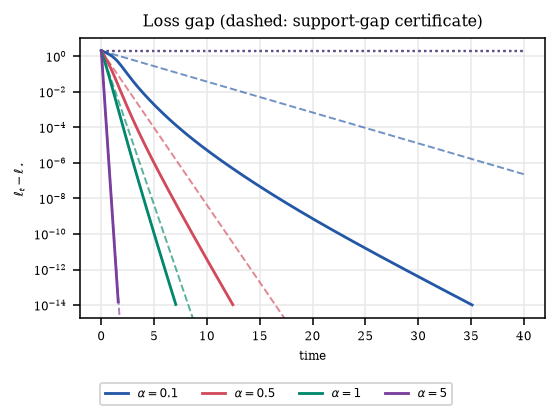

In [6]:
fig = plot_scale_sweep(isotropic_results_by_scale, d_u=d_u, d_v=d_v, kappa=PL_KAPPA)
save_figure(fig, FIG_DIR / "bures_smooth_lasso_scale_sweep.pdf")
plt.show()

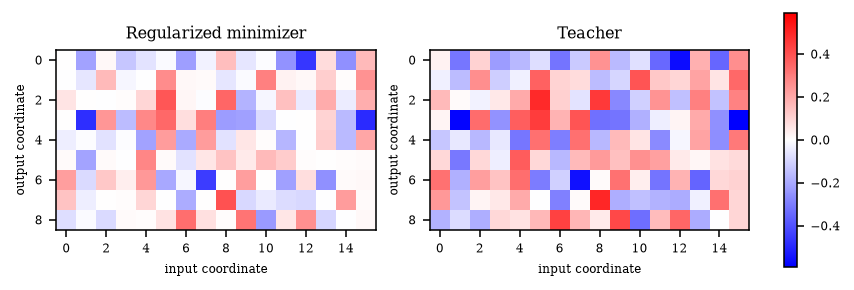

In [7]:
fig, axes = plt.subplots(1, 2, figsize=TWO_PANEL_SIZE, constrained_layout=True)
limit = float(np.max(np.abs(oracle_uv)))
for ax, matrix, title in zip(axes, [regularized_minimizer_vu(oracle_uv), oracle_uv.T],
                              ["Regularized minimizer", "Teacher"]):
    image = ax.imshow(matrix, cmap="bwr", vmin=-limit, vmax=limit)
    ax.set(title=title, xlabel="input coordinate", ylabel="output coordinate")
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()


## Internal coarse bound versus spectral certificate

For white initialization, the paper's coarse bound uses
$$c_\alpha(M)=\alpha\left(\frac{\alpha}{\sqrt{m\alpha^2+2M^2}+M}\right)^{m-1}.$$
The 1-strongly convex objective gives an a priori initial-sublevel radius
$M=\|S_0\|_F+2\sqrt{2\Delta_0}$, so no observed trajectory maximum is used.
The exponent comparison below reuses the existing scale runs; this is an internal comparison, not a prior-work benchmark.


In [8]:
coarse_comparison = [summarize_result(f"alpha={alpha:g}", result, alpha=alpha, d_u=d_u, d_v=d_v)
                     for alpha, result in isotropic_results_by_scale.items()]
coarse_comparison


[{'label': 'alpha=0.1',
  'initial_loss': np.float64(2.057113635217927),
  'final_loss': np.float64(3.083182522511271e-16),
  'initial_distance_to_minimizer_fro': np.float64(1.9804364726240018),
  'final_distance_to_minimizer_fro': np.float64(2.4435867848037186e-08),
  'tail_loss_rate': 0.8597201175930914,
  'tail_error_rate': 0.3953336261751751,
  'min_eig_sigma_final': np.float64(0.004723640028013777),
  'max_signed_spectrum_drift': 4.747393848404441e-10,
  'success': True,
  'nfev': 1880,
  'support_gap': 0.2,
  'certified_loss_rate': 0.4,
  'M_bound': 4.056711609388005,
  'c_coarse': 1.5634559874659983e-49,
  'coarse_loss_rate': 6.253823949863993e-49,
  'coarse_over_spectral': 1.5634559874659982e-48},
 {'label': 'alpha=0.5',
  'initial_loss': np.float64(2.057113635217927),
  'final_loss': np.float64(2.0964371085818297e-20),
  'initial_distance_to_minimizer_fro': np.float64(1.9804364726240018),
  'final_distance_to_minimizer_fro': np.float64(6.337925077478022e-11),
  'tail_loss_rate

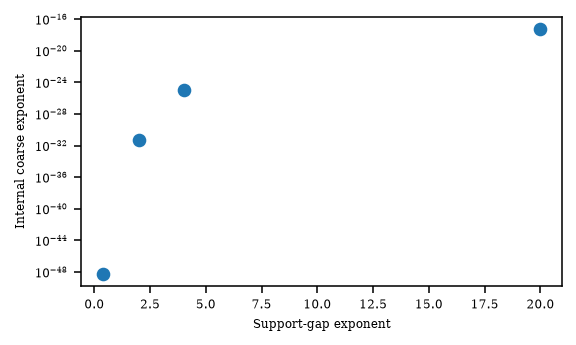

In [9]:
fig, ax = plt.subplots(figsize=SINGLE_PANEL_SIZE, constrained_layout=True)
ax.semilogy([r["certified_loss_rate"] for r in coarse_comparison],
            [r["coarse_loss_rate"] for r in coarse_comparison], "o")
ax.set(xlabel="Support-gap exponent", ylabel="Internal coarse exponent")
plt.show()


## General covariance conditioning

The paired diagonal perturbation has $g(\Sigma_0)=2r$. Thus every $r>0$ has a certified rate $4r\kappa$, without any isotropy identity. At $r=0$, both a matched input and output direction are absent and $g=0$: this is outside the positive-gap theorem. It must not be confused with a one-sided singular positive-gap initialization, illustrated separately below.


In [10]:
perturb_scales = np.linspace(0., 1.0, 9)
perturbed_results_by_scale: dict[float, FlowResult] = {}

for scale in perturb_scales:
    sigma0=identity_covariance(d_u, d_v, scale=1.0)
    for i in range(1):
        sigma0[i, i] *= scale
        sigma0[i+d_u, i+d_u] *= scale
    cfg = FlowConfig(
        d_u=d_u,
        d_v=d_v,
        oracle_uv=oracle_uv,
        sigma0=sigma0,
        t_final=40.0,
        n_eval=801,
    )
    perturbed_results_by_scale[scale] = solve_bures_flow(cfg)

scale_summary = [
    summarize_result(
        f"scale={scale:g}",
        res,
        alpha=scale,
        d_u=d_u,
        d_v=d_v,
        kappa=PL_KAPPA,
    )
    for scale, res in perturbed_results_by_scale.items()
]
scale_summary;

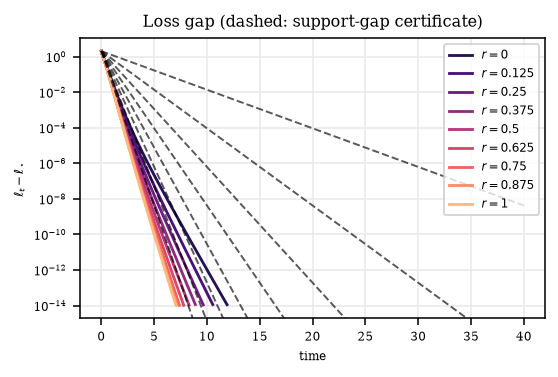

In [11]:
fig=plot_scale_sweep(perturbed_results_by_scale, d_u=d_u, d_v=d_v, kappa=PL_KAPPA, parameter_label="r", plot_coarse_rate=[], plot_spectral_rate=None, colors = "magma", line_colors = ['k', ], show_legend=False)
plt.legend(loc = "upper right")
save_figure(fig, FIG_DIR / "bures_smooth_lasso_perturb_sweep.pdf")
plt.show()

## Finite-Width Particle Gradient Flow

The finite-width model evolves individual particles $x_i=(u_i,v_i)$ rather than the covariance directly. For width $n$, initialize

$$
\nu_0^n=\frac1n\sum_{i=1}^n\delta_{(u_i(0),v_i(0))},
\qquad
\nu_0^n\approx \mathcal N(0,\alpha I),
$$

iid across particles, so the empirical covariance starts near $\alpha I$. The empirical predictor is

$$
\widehat S_{vu}=\frac1n VU^\top,
$$

where `U` and `V` store particles in columns. With the smooth-lasso predictor gradient $E=\nabla\ell(\widehat S_{vu})$, we use the mean-field particle scaling

$$
\dot u_i=-E^\top v_i,
\qquad
\dot v_i=-E u_i.
$$

Each empirical covariance obeys exactly the same closed ODE. Sampling enters through its initial covariance, support gap, and loss gap; the population exponent cannot simply be reused for every sample. The summary below reports the realized gaps and each run is checked against its own envelope. Thin lines are trials, thick lines arithmetic means, and shading is one sample standard deviation (not a confidence interval). Covariance distance from the population flow is a descriptive sampling diagnostic, not the convergence theorem.


In [12]:
finite_alpha = 1.0
finite_widths = [32, 128, 512, 2048]
finite_n_repeats = 5
finite_t_final = 40.0
finite_n_eval = 501

mean_field_config = FlowConfig(
    d_u=d_u,
    d_v=d_v,
    oracle_uv=oracle_uv,
    sigma0=identity_covariance(d_u, d_v, scale=finite_alpha),
    t_final=finite_t_final,
    n_eval=finite_n_eval,
)
mean_field_result = solve_bures_flow(mean_field_config)

particle_results_by_width: dict[int, list[ParticleResult]] = {}
for n_particles in finite_widths:
    repeats = []
    for repeat in range(finite_n_repeats):
        cfg = ParticleConfig(
            d_u=d_u,
            d_v=d_v,
            oracle_uv=oracle_uv,
            n_particles=n_particles,
            alpha=finite_alpha,
            rng_seed=10_000 + 1_000 * n_particles + repeat,
            t_final=finite_t_final,
            n_eval=finite_n_eval,
        )
        repeats.append(solve_particle_flow(cfg))
    particle_results_by_width[n_particles] = repeats

finite_width_summary = []
for n_particles, repeats in particle_results_by_width.items():
    loss_stack = np.vstack([result.loss for result in repeats])
    covariance_error_stack = np.vstack([
        np.linalg.norm(result.sigma - mean_field_result.sigma, ord="fro", axis=(1, 2))
        for result in repeats
    ])
    finite_width_summary.append({
        "n_particles": n_particles,
        "n_repeats": len(repeats),
        "initial_gap_mean": float(np.mean([support_gap(r.sigma[0], d_u) for r in repeats])),
        "initial_gap_std": float(np.std([support_gap(r.sigma[0], d_u) for r in repeats], ddof=1)),
        "initial_loss_mean": float(np.mean(loss_stack[:, 0])),
        "initial_loss_std": float(np.std(loss_stack[:, 0], ddof=1)),
        "final_loss_mean": float(np.mean(loss_stack[:, -1])),
        "final_loss_std": float(np.std(loss_stack[:, -1], ddof=1)),
        "initial_covariance_error_fro_mean": float(np.mean(covariance_error_stack[:, 0])),
        "initial_covariance_error_fro_std": float(np.std(covariance_error_stack[:, 0], ddof=1)),
        "final_covariance_error_fro_mean": float(np.mean(covariance_error_stack[:, -1])),
        "final_covariance_error_fro_std": float(np.std(covariance_error_stack[:, -1], ddof=1)),
        "all_success": all(result.success for result in repeats),
        "total_nfev": int(sum(result.nfev for result in repeats)),
    })
finite_width_summary


[{'n_particles': 32,
  'n_repeats': 5,
  'initial_gap_mean': 0.1895083898553277,
  'initial_gap_std': 0.051467745080834855,
  'initial_loss_mean': 6.199620677590554,
  'initial_loss_std': 0.8704762402928808,
  'final_loss_mean': 8.818417308338279e-17,
  'final_loss_std': 8.257124611939413e-17,
  'initial_covariance_error_fro_mean': 4.616581216862531,
  'initial_covariance_error_fro_std': 0.16105084423690866,
  'final_covariance_error_fro_mean': 3.19968530609864,
  'final_covariance_error_fro_std': 0.21301741229920784,
  'all_success': True,
  'total_nfev': 15868},
 {'n_particles': 128,
  'n_repeats': 5,
  'initial_gap_mean': 0.9648039141072374,
  'initial_gap_std': 0.05540730059555308,
  'initial_loss_mean': 3.738558688202101,
  'initial_loss_std': 0.45616188625048304,
  'final_loss_mean': 1.2324313139273168e-17,
  'final_loss_std': 6.279446066007007e-18,
  'initial_covariance_error_fro_mean': 2.3295194094878866,
  'initial_covariance_error_fro_std': 0.07503589630416159,
  'final_covar

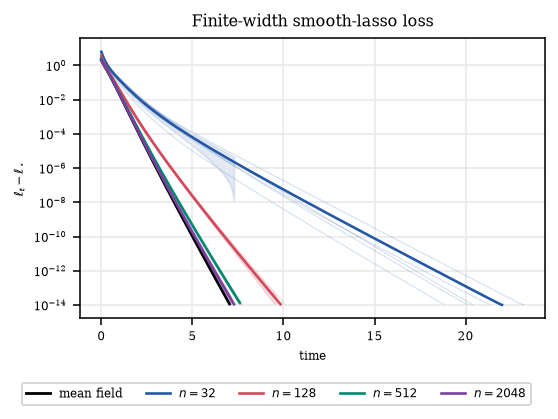

In [13]:
fig = plot_finite_width_comparison(
    mean_field_result,
    particle_results_by_width,
)
save_figure(fig, FIG_DIR / "bures_smooth_lasso_finite_width_comparison.pdf")
plt.show()

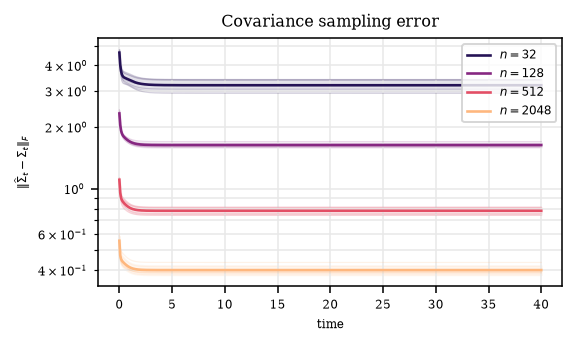

In [14]:
fig = plot_finite_width_covariance_error(
    mean_field_result,
    particle_results_by_width,
    colors="magma",
)
plt.show()


## Appendix counterpart of Figure 2

The three panels match the quadratic Figure 2: white initialization scales, paired covariance perturbations, and finite-width sampling. Panel (b) shows only the white-reference certificate, as in Figure 2; all positive-gap cases were checked in the validation cell against their own envelopes. Panel (c) uses individual trials and their arithmetic mean, matching the main figure.

The triptych uses a y-axis minimum of $10^{-23}$ and raw positive loss gaps, without the $10^{-14}$ cutoff of the single-panel plots. A tolerance sweep found typical covariance tails near $10^{-20}$ and width-32 factor tails near $10^{-16}$ at the configured tolerances; tightening relative/absolute tolerances by 100 lowered those medians by roughly four decades. These late-time plateaus and isolated lower dips are numerical, not certified asymptotic rates. The tolerance-sweep results are saved in `results/bures_mean_field_smooth_lasso/tolerance_sweep.json`.


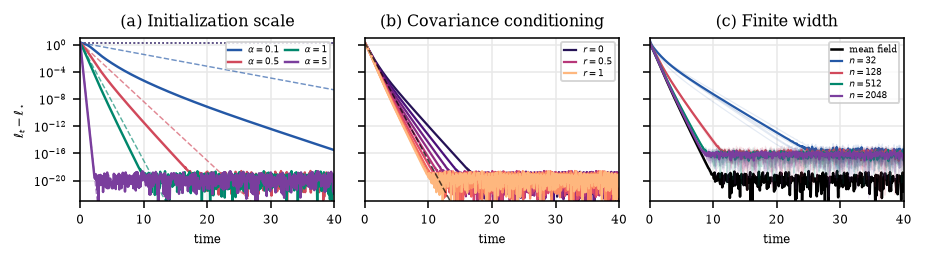

In [15]:
# Appendix counterpart of Figure 2: same dimensions, teacher, panels, and scales.
fig, axes = plt.subplots(1, 3, figsize=(6.5, 1.6875), sharey=True)
fig.subplots_adjust(left=0.075, right=0.98, bottom=0.19, top=0.88, wspace=0.12)

ax = axes[0]
for color, (alpha, result) in zip(COLORS, isotropic_results_by_scale.items()):
    ax.plot(result.t, result.loss, color=color, linewidth=1.25, label=rf"$\alpha={alpha:g}$")
    gap = support_gap(result.sigma[0], d_u)
    ax.plot(result.t, result.loss[0]*np.exp(-2*PL_KAPPA*gap*result.t),
            "--", color=color, linewidth=0.75, alpha=0.65)
    radius = sublevel_radius_bound(result, d_u, d_v)
    coarse = coarse_ellipticity_constant(alpha, d_u+d_v, radius)
    ax.plot(result.t, result.loss[0]*np.exp(-4*PL_KAPPA*coarse*result.t),
            ":", color=color, linewidth=0.8, alpha=0.8)
finish_axes(ax, title="(a) Initialization scale", ylabel=r"$\ell_t-\ell_\star$")
ax.legend(loc="upper right", ncol=2, fontsize=4.6, frameon=True,
          borderpad=0.25, labelspacing=0.2, columnspacing=0.55, handlelength=1.4)

ax = axes[1]
for color, (r, result) in zip(resolve_plot_colors("magma", len(perturbed_results_by_scale)),
                             perturbed_results_by_scale.items()):
    label = rf"$r={r:g}$" if np.isclose(r, [0., 0.5, 1.]).any() else "_nolegend_"
    ax.plot(result.t, result.loss, color=color, linewidth=1.15, label=label)
reference = perturbed_results_by_scale[1.]
ax.plot(reference.t, reference.loss[0]*np.exp(-4*PL_KAPPA*reference.t),
        "--", color="black", linewidth=0.8, alpha=0.7)
finish_axes(ax, title="(b) Covariance conditioning", ylabel=None)
ax.legend(loc="upper right", fontsize=4.6, frameon=True,
          borderpad=0.25, labelspacing=0.2, handlelength=1.4)

ax = axes[2]
ax.plot(mean_field_result.t, mean_field_result.loss, color="black", linewidth=1.3, label="mean field")
for color, (width, repeats) in zip(COLORS, particle_results_by_width.items()):
    t, mean, _ = finite_width_curve_stats(repeats)
    for result in repeats:
        ax.plot(t, result.loss, color=color, linewidth=0.6, alpha=0.12)
    ax.plot(t, mean, color=color, label=rf"$n={width}$", linewidth=1.15)
finish_axes(ax, title="(c) Finite width", ylabel=None)
ax.legend(loc="upper right", fontsize=4.4, frameon=True,
          borderpad=0.25, labelspacing=0.18, handlelength=1.3)
# Include solver-dependent tails; do not apply the single-panel display cutoff.
axes[0].set_ylim(1e-23, 10.)
for ax in axes:
    ax.set_xlim(0., 40.)
save_figure(fig, FIG_DIR / "bures_smooth_lasso_triptych")
plt.show()


## One-sided singular initialization

Only the smaller output block is initialized, with variance $2\alpha$. The covariance has rank $d_v=9<25$, but $g=2\alpha=2$ and the initial predictor is exactly zero. The loss therefore has the same certified exponent as full-white variance $\alpha=1$. This changes the initialization; it is not a claim that low-width full-white sampling retains that exponent.


In [16]:
# Keep the teacher and saved population trajectory unchanged.
# Initialize only the smaller (output) block at twice the full-white variance.
singular_sigma0 = np.diag(np.r_[np.zeros(d_u), 2*finite_alpha*np.ones(d_v)])
singular_config = FlowConfig(d_u=d_u, d_v=d_v, oracle_uv=oracle_uv,
                            sigma0=singular_sigma0, t_final=40.0)
singular_result = solve_bures_flow(singular_config)
print({"covariance_rank": int(np.linalg.matrix_rank(singular_sigma0)),
       "support_gap": support_gap(singular_sigma0, d_u),
       "certified_exponent": 2*PL_KAPPA*support_gap(singular_sigma0, d_u),
       "final_loss_gap": singular_result.loss[-1]})


{'covariance_rank': 9, 'support_gap': 2.0000000000000004, 'certified_exponent': 4.000000000000001, 'final_loss_gap': np.float64(2.4674112132003613e-21)}


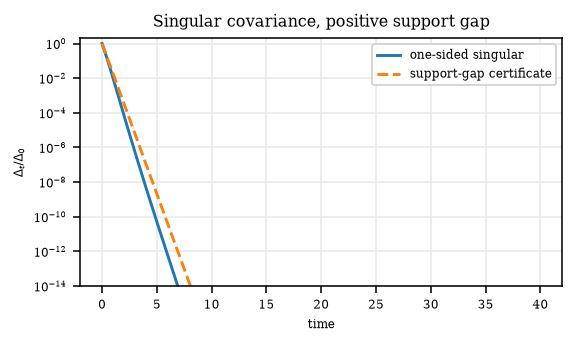

In [17]:
fig, ax = plt.subplots(figsize=SINGLE_PANEL_SIZE, constrained_layout=True)
ax.plot(singular_result.t, visible(singular_result.loss/singular_result.loss[0]), label="one-sided singular")
ax.plot(singular_result.t, np.exp(-2*PL_KAPPA*support_gap(singular_sigma0, d_u)*singular_result.t),
        "--", label="support-gap certificate")
finish_axes(ax, title="Singular covariance, positive support gap", ylabel=r"$\Delta_t/\Delta_0$", legend={"loc":"best"})
ax.set_ylim(DISPLAY_FLOOR, 2)
save_figure(fig, FIG_DIR / "bures_smooth_lasso_singular")
plt.show()


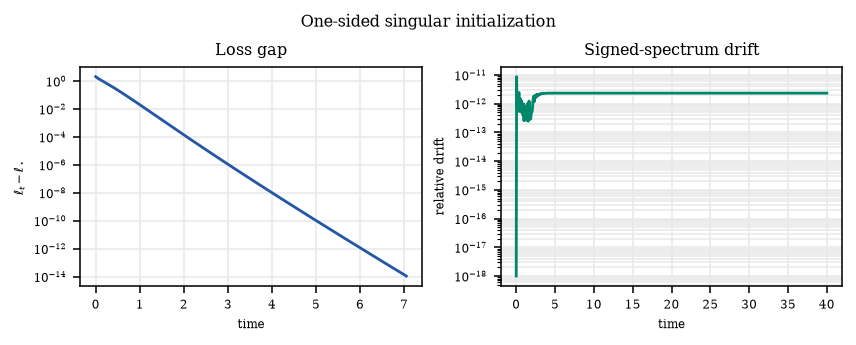

In [18]:
plot_trajectory(singular_result, title="One-sided singular initialization")


## Validation and saved results

The checks below cover the nonquadratic gradient, PL inequality, minimizer stationarity, exact factor/covariance closure, conservation of the signed spectrum, and the support-gap envelopes. A non-isotropic covariance with a nonzero cross block is included so an isotropy-only diagnostic cannot pass accidentally. Tolerances are numerical allowances, not mathematical proof. Stored gaps are not display-clipped. The saved teacher, minimizer, initial covariance, and loss parameters come from the same population run; all finite-width seeds and initial gaps are also exported.


In [19]:
import json
import platform
import scipy
import matplotlib

check_rng = np.random.default_rng(20260924)
s_reg, ell_star = objective_minimum(oracle_uv, LASSO_LAMBDA, LASSO_DELTA)
_, stationary_gradient = predictor_objective_and_gradient_vu(s_reg, oracle_uv)
assert np.linalg.norm(stationary_gradient) < 1e-14
# The omitted linear residual term is bounded by ||grad ell(z)|| ||x-z||;
# ell(z)-ell_star <= ||grad ell(z)||^2/(2 kappa). At a Bregman gap
# equal to the plot minimum, strong convexity gives ||x-z|| <= sqrt(2 gap).
root_residual = float(np.linalg.norm(stationary_gradient))
root_gap_error_at_plot_minimum = root_residual*np.sqrt(2e-23) + root_residual**2/2
assert root_gap_error_at_plot_minimum < 1e-26
# Diagonal Hessian bounds justify kappa=1, L=1+lambda/delta.
for entry in [0., LASSO_DELTA, 1., -3.]:
    curvature = 1+LASSO_LAMBDA*LASSO_DELTA**2/(entry**2+LASSO_DELTA**2)**1.5
    assert PL_KAPPA <= curvature <= SMOOTHNESS_L+1e-14
for _ in range(12):
    x = check_rng.normal(size=(d_v, d_u))
    direction = check_rng.normal(size=x.shape)
    direction /= np.linalg.norm(direction)
    objective, gradient = predictor_objective_and_gradient_vu(x, oracle_uv)
    eps = 1e-5
    plus = predictor_objective_and_gradient_vu(x+eps*direction, oracle_uv)[0]
    minus = predictor_objective_and_gradient_vu(x-eps*direction, oracle_uv)[0]
    np.testing.assert_allclose((plus-minus)/(2*eps), np.sum(gradient*direction), rtol=1e-6, atol=1e-8)
    gap = stable_loss_gap(x, s_reg, LASSO_LAMBDA, LASSO_DELTA)
    np.testing.assert_allclose(gap, objective-ell_star, rtol=1e-12, atol=1e-11)
    assert np.sum(gradient**2) >= 2*PL_KAPPA*gap-1e-9
# Near the minimizer, the stable gap obeys strong-convexity/smoothness bounds.
x = s_reg + 1e-9*check_rng.normal(size=s_reg.shape)
near_gap = stable_loss_gap(x, s_reg, LASSO_LAMBDA, LASSO_DELTA)
squared_distance = np.sum((x-s_reg)**2)
assert 0.5*squared_distance <= near_gap <= 0.5*SMOOTHNESS_L*squared_distance

# Exact closure checked on an independent, non-isotropic rectangular example.
cu, cv, cn = 3, 2, 12
w = check_rng.normal(size=(cu+cv, cn))
w[:cu] *= 1.7
small_teacher = random_oracle_uv(cu, cv, check_rng)
covariance0 = w@w.T/cn
factor_field = particle_rhs_flat(0, w.ravel(), cu, cv, cn, small_teacher, LASSO_LAMBDA, LASSO_DELTA).reshape(w.shape)
np.testing.assert_allclose((factor_field@w.T+w@factor_field.T)/cn,
                          bures_rhs_matrix(covariance0, cu, cv, small_teacher), rtol=1e-12, atol=1e-12)
small_flow = solve_bures_flow(FlowConfig(cu, cv, small_teacher, covariance0, t_final=3, n_eval=101))
small_particles = solve_particle_flow(ParticleConfig(cu, cv, small_teacher, cn, 1.,
    u0=w[:cu], v0=w[cu:], t_final=3, n_eval=101, rtol=1e-10, atol=1e-12))
closure_error = float(np.max(np.abs(small_flow.sigma-small_particles.sigma)))
assert closure_error < 2e-7
assert np.max(small_flow.signed_spectrum_drift) < 2e-7
# Regression check: Sigma J Sigma itself is not a conserved matrix in general.
j_small = signature_matrix(cu, cv)
assert np.linalg.norm(small_flow.sigma[-1]@j_small@small_flow.sigma[-1]-covariance0@j_small@covariance0) > 1e-3
np.testing.assert_allclose(support_gap(singular_sigma0, d_u), 2*finite_alpha, atol=1e-12)
np.testing.assert_allclose(support_gap(perturbed_results_by_scale[0.].sigma[0], d_u), 0., atol=1e-12)

certificate_checks = []
def check_envelope(label, result, du):
    g0 = support_gap(result.sigma[0], du)
    bound = result.loss[0]*np.exp(-2*PL_KAPPA*g0*result.t)
    # Absolute allowance is necessary below solver precision.
    tolerance = 2e-7*max(1., result.loss[0])
    excess = float(np.max(result.loss-bound))
    assert result.success and excess <= tolerance, (label, excess)
    assert np.min(result.min_eig_sigma) >= -tolerance
    certificate_checks.append({"label": label, "initial_gap": g0,
        "initial_loss": float(result.loss[0]), "maximum_envelope_excess": excess,
        "numerical_tolerance": float(tolerance)})

for alpha, result in isotropic_results_by_scale.items():
    check_envelope(f"white variance {alpha:g}", result, d_u)
for r, result in perturbed_results_by_scale.items():
    check_envelope(f"paired perturbation {r:g}", result, d_u)
check_envelope("one-sided singular", singular_result, d_u)
check_envelope("general cross-block covariance", small_flow, cu)
for width, repeats in particle_results_by_width.items():
    for trial, result in enumerate(repeats):
        check_envelope(f"width {width}, trial {trial}", result, d_u)
all_flows = [*isotropic_results_by_scale.values(), *perturbed_results_by_scale.values(),
             singular_result, mean_field_result, small_flow]
for alpha, result in isotropic_results_by_scale.items():
    assert np.max(predictor_block_norms(result, d_u, d_v)) <= sublevel_radius_bound(result, d_u, d_v)+1e-8
    np.testing.assert_allclose(support_gap(result.sigma[0], d_u), 2*alpha)
max_spectrum_drift = float(max(np.max(r.signed_spectrum_drift) for r in all_flows))
assert max_spectrum_drift < 2e-6

output_dir = RESULTS_DIR / "bures_mean_field_smooth_lasso"
output_dir.mkdir(parents=True, exist_ok=True)
trajectory = mean_field_result
np.savez_compressed(output_dir / "identity_smooth_lasso_trajectory.npz",
    t=trajectory.t, sigma=trajectory.sigma, loss=trajectory.loss,
    predictor_error_fro=trajectory.predictor_error_fro,
    min_eig_sigma=trajectory.min_eig_sigma, signed_spectrum_drift=trajectory.signed_spectrum_drift,
    oracle_uv=mean_field_config.oracle_uv, sigma0=mean_field_config.sigma0,
    lasso_lambda=mean_field_config.lasso_lambda, lasso_delta=mean_field_config.lasso_delta,
    s_reg=s_reg, ell_star=ell_star, kappa=PL_KAPPA, smoothness=SMOOTHNESS_L,
    support_gap=support_gap(mean_field_config.sigma0, d_u))
np.savez_compressed(output_dir / "finite_width_smooth_lasso.npz",
    t=mean_field_result.t, widths=np.array(finite_widths), oracle_uv=oracle_uv,
    lasso_lambda=LASSO_LAMBDA, lasso_delta=LASSO_DELTA,
    loss=np.array([[r.loss for r in particle_results_by_width[n]] for n in finite_widths]),
    initial_support_gap=np.array([[support_gap(r.sigma[0], d_u) for r in particle_results_by_width[n]] for n in finite_widths]),
    seeds=np.array([[10000+1000*n+j for j in range(finite_n_repeats)] for n in finite_widths]))
verification = {"python": platform.python_version(), "numpy": np.__version__,
    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
    "parameters": {"du": d_u, "dv": d_v, "lambda": LASSO_LAMBDA, "delta": LASSO_DELTA,
                   "kappa": PL_KAPPA, "L": SMOOTHNESS_L, "teacher_seed": 0,
                   "covariance_rtol": 1e-9, "covariance_atol": 1e-11,
                   "factor_rtol": 1e-8, "factor_atol": 1e-10, "method": "RK45"},
    "max_factor_covariance_error": closure_error, "max_signed_spectrum_relative_drift": max_spectrum_drift,
    "minimizer_gradient_norm": float(np.linalg.norm(stationary_gradient)),
    "root_gap_error_bound_at_plot_minimum": root_gap_error_at_plot_minimum,
    "finite_width_summary": finite_width_summary, "certificate_checks": certificate_checks}
(output_dir / "verification.json").write_text(json.dumps(verification, indent=2, allow_nan=False)+"\n")
print({"checked_envelopes": len(certificate_checks),
       "max_factor_covariance_error": closure_error,
       "max_signed_spectrum_relative_drift": max_spectrum_drift,
       "output_directory": str(output_dir)})


{'checked_envelopes': 35, 'max_factor_covariance_error': 7.186590541413684e-10, 'max_signed_spectrum_relative_drift': 4.747393848404441e-10, 'output_directory': '/Users/stephen.zhang/Projects/linear-networks-global/python/results/bures_mean_field_smooth_lasso'}
